# 📓 Multimodal AI Module 4: Discrete Tokenization & "Everything as a Token"
Welcome to Module 4! In the previous tutorial (LLaVA), we kept multimodal features in a **continuous embedding space**. Here, we transition to the **"Everything as a Token"** paradigm [cite: 8].

Modern omni-modal models (like **AnyGPT**, **SpeechTokenizer**, and **SEED**) map continuous sensory signals (images, audio) into sequences of **discrete integer IDs** [cite: 8]. By assigning these discrete IDs a spot in an expanded LLM vocabulary, a standard text-based Transformer can natively predict raw audio and pixels!

---

## 💡 1. Vector Quantization (VQ) Foundations

Instead of keeping the continuous latent vector $z \in \mathbb{R}^D$, a Vector Quantized Variational Autoencoder (**VQ-VAE** or **VQ-GAN**) forces the latent vector to be snapped to the nearest entry in a learned discrete **Codebook** $\mathcal{C} = \{e_1, e_2, \dots, e_K\}$ where $K$ is the vocabulary size [cite: 8].

### The Process:
1. **Encode:** An image $x$ is mapped to continuous latent patches $z(x)$.
2. **Quantize (Tokenize):** Each patch vector $z_i$ is replaced by the nearest codebook vector $e_k$ via Euclidean distance:
   $$k = \arg\min_{j \in \{1 \dots K\}} \|z_i - e_j\|_2$$
   The image is now just a sequence of integers: `[45, 1024, 8, ..., 310]`.
3. **Decode (Untokenize):** The sequence of IDs fetches the corresponding vectors from the codebook, which a decoder neural network converts back into raw RGB pixels [cite: 8].

In [2]:
!pip uninstall -y -q torchao

# Install dependencies if running in Colab/Jupyter
try:
    import diffusers
except ImportError:
    !pip install -q diffusers transformers accelerate torch torchvision pillow matplotlib ipywidgets

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import urllib.request
import io

from diffusers import VQModel
from torchvision import transforms
from IPython.display import display, clear_output
import ipywidgets as widgets
from ipywidgets import interact, IntSlider, FloatSlider

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing on device: {device}")

Executing on device: cuda


## 📦 2. Initializing the Tokenizer/Untokenizer (VQ-GAN)
We load a lightweight, pre-trained VQ-GAN model. This architecture compresses a $256 \times 256$ image into a $16 \times 16$ grid of discrete tokens (256 tokens total) mapped against a codebook of size $K=16384$.

Loading VQ-GAN Tokenizer/Untokenizer...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
An error occurred while trying to fetch compvis/ldm-super-resolution-4x-openimages: compvis/ldm-super-resolution-4x-openimages does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


VQ-GAN initialized! Codebook contains 8192 vectors of dimension 3.


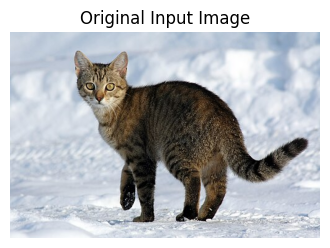

In [3]:
# Load lightweight pre-trained VQ-GAN from Hugging Face Diffusers
print("Loading VQ-GAN Tokenizer/Untokenizer...")
vq_model = VQModel.from_pretrained("compvis/ldm-super-resolution-4x-openimages", subfolder="vqvae").to(device)
vq_model.eval()

codebook_size = vq_model.quantize.embedding.weight.shape[0]
codebook_dim = vq_model.quantize.embedding.weight.shape[1]
print(f"VQ-GAN initialized! Codebook contains {codebook_size} vectors of dimension {codebook_dim}.")

# Fetch a real test image
url = "https://upload.wikimedia.org/wikipedia/commons/thumb/b/b6/Felis_catus-cat_on_snow.jpg/500px-Felis_catus-cat_on_snow.jpg"
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as resp:
    raw_image = Image.open(io.BytesIO(resp.read())).convert("RGB")

# Image preprocessing transformation
preprocess = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]) # Map [0,1] -> [-1, 1]
])

pixel_tensor = preprocess(raw_image).unsqueeze(0).to(device)  # [1, 3, 256, 256]

plt.figure(figsize=(4,4))
plt.imshow(raw_image)
plt.title("Original Input Image")
plt.axis("off")
plt.show()

## 🔢 3. Tokenization: Pixels to Discrete IDs
We pass the continuous image through the VQ-GAN encoder and snap the continuous latent grids to their nearest neighbor indices in the codebook.

In [6]:
with torch.no_grad():
    # 1. Encode into continuous latents
    continuous_latents = vq_model.encoder(pixel_tensor)
    continuous_latents = vq_model.quant_conv(continuous_latents)
    print(f"Continuous Latent Grid Shape: {continuous_latents.shape}") # [1, 3, 64, 64]

    # 2. Tokenize: Map latents to discrete codebook indices
    # Note: VQModel expects [B, C, H, W] but quantization operates on the channel dimension C
    B, C, H, W = continuous_latents.shape
    flat_latents = continuous_latents.permute(0, 2, 3, 1).reshape(-1, C)  # [B*H*W, C]

    # Compute L2 distances: (z - e)^2 = z^2 + e^2 - 2ze
    codebook = vq_model.quantize.embedding.weight
    distances = (
        torch.sum(flat_latents**2, dim=1, keepdim=True)
        + torch.sum(codebook**2, dim=1)
        - 2 * torch.matmul(flat_latents, codebook.t())
    )

    # Find the nearest codebook index for each spatial patch
    token_ids = torch.argmin(distances, dim=1)
    token_grid = token_ids.view(B, H, W)
    print(f"Discrete Token Grid Shape : {token_grid.shape}") # [1, 64, 64]

# Print a subset of the 1D discrete sequence (like a text sentence!)
sequence_1d = token_ids.cpu().numpy().tolist()
print("\nVisual Token Sequence (First 30 IDs):")
print(sequence_1d[:30], "...")

Continuous Latent Grid Shape: torch.Size([1, 3, 64, 64])
Discrete Token Grid Shape : torch.Size([1, 64, 64])

Visual Token Sequence (First 30 IDs):
[4371, 7432, 2971, 7865, 4371, 7012, 1145, 2971, 217, 6107, 6415, 6622, 6579, 2124, 2348, 217, 6870, 3378, 2286, 1919, 3650, 2363, 1699, 25, 8067, 1148, 6443, 6930, 5169, 956] ...


## 🎨 4. De-Tokenization: IDs back to Pixels
Now, we perform the exact reverse. We take our list of integer `token_ids`, look up their embeddings in the codebook, and feed them through the decoder network to reconstruct the RGB image [cite: 8].

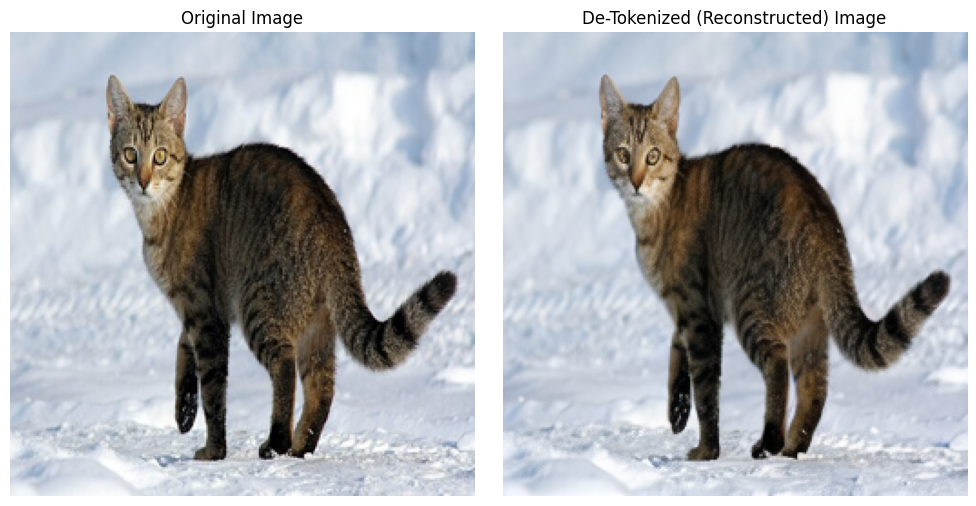

In [7]:
def untokenize(discrete_ids, height, width):
    """Reconstructs an image from a 1D list of discrete token IDs."""
    with torch.no_grad():
        # Look up continuous embeddings from the codebook
        quantized_latents = vq_model.quantize.embedding(discrete_ids)
        # Reshape back to grid [B, C, H, W]
        quantized_latents = quantized_latents.view(1, height, width, -1).permute(0, 3, 1, 2)

        # Decode back to pixels
        post_quant_conv = vq_model.post_quant_conv(quantized_latents)
        reconstructed = vq_model.decoder(post_quant_conv)

        # Post-process: [-1, 1] -> [0, 1] -> [0, 255] RGB
        reconstructed = (reconstructed / 2 + 0.5).clamp(0, 1)
        reconstructed = reconstructed.squeeze(0).permute(1, 2, 0).cpu().numpy()
        return (reconstructed * 255).astype(np.uint8)

# Untokenize the sequence back into an image
reconstructed_img = untokenize(token_ids, H, W)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(raw_image.resize((256,256)))
ax1.set_title("Original Image")
ax1.axis("off")

ax2.imshow(reconstructed_img)
ax2.set_title("De-Tokenized (Reconstructed) Image")
ax2.axis("off")
plt.tight_layout()
plt.show()

## 🛡️ 5. Diagnostic Lab: Spatial Robustness of Visual Tokens

Unlike continuous vector corruption (which affects the global embedding), **discrete token sequences** degrade locally.
If a Language Model hallucinates or mispredicts 20% of the visual tokens during image generation, what does the resulting image look like?

Use the slider to randomly corrupt a percentage of the discrete tokens by replacing them with random IDs from the codebook.

In [7]:
def token_corruption_lab(corruption_rate=0.20):
    corrupted_ids = token_ids.clone()

    # Randomly select indices to corrupt
    num_corrupt = int(corruption_rate * len(corrupted_ids))
    if num_corrupt > 0:
        corrupt_indices = torch.randperm(len(corrupted_ids))[:num_corrupt]
        # Replace with random codebook IDs [0, 16383]
        random_tokens = torch.randint(0, codebook_size, (num_corrupt,), device=device)
        corrupted_ids[corrupt_indices] = random_tokens

    # Untokenize the corrupted sequence
    corrupted_img = untokenize(corrupted_ids, H, W)

    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(corrupted_img)
    ax.set_title(f"Reconstructed Image ({corruption_rate*100:.0f}% Tokens Corrupted)", fontsize=12, fontweight='bold')
    ax.axis("off")
    plt.show()

    print("Notice how discrete token corruption causes localized structural artifacts (wrong colors/textures in specific grid cells)")
    print("rather than a global color shift or blur. This is a defining characteristic of VQ tokenization!")

interact(token_corruption_lab,
         corruption_rate=FloatSlider(value=0.15, min=0.0, max=0.8, step=0.05, description='Corruption:'));

interactive(children=(FloatSlider(value=0.15, description='Corruption:', max=0.8, step=0.05), Output()), _dom_…

## 🔗 6. AnyGPT/SEED Simulation: LLM Multimodal Interleaving
Once sensory signals are discrete tokens, we simply expand the LLM tokenizer vocabulary:

$$\mathcal{V}_{unified} = \mathcal{V}_{text} \cup \mathcal{V}_{vision} \cup \mathcal{V}_{audio}$$

We use **Modal Modifiers** (special delimiter tags) to instruct the LLM on which modality it is reading or generating.

We will fine-tune a small standard Language Model (`distilgpt2`) to predict visual token IDs autoregressively given a text prompt. The loss is computed *only* on the visual token sequence, masking out the text prompt.

In [9]:
from torchvision.datasets import CIFAR10
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_ID = "distilgpt2"  # Fast, lightweight causal LM (82M params)

print("Loading LLM backbone and expanding unified vocabulary...")
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_ID)
llm_model = AutoModelForCausalLM.from_pretrained(LLM_ID).to(device)

# Add multimodal boundary tokens
special_tokens = {"additional_special_tokens": ["<|start_img|>", "<|end_img|>"]}
llm_tokenizer.add_special_tokens(special_tokens)
llm_tokenizer.pad_token = llm_tokenizer.eos_token

START_IMG_ID = llm_tokenizer.convert_tokens_to_ids("<|start_img|>")
END_IMG_ID = llm_tokenizer.convert_tokens_to_ids("<|end_img|>")

# Expand LLM vocabulary to include all VQ-GAN codebook entries
# TEXT_VOCAB_SIZE = len(llm_tokenizer)
TEXT_VOCAB_SIZE = max(llm_tokenizer.vocab.values()) + 1

CODEBOOK_SIZE = vq_model.quantize.embedding.weight.shape[0]  # 16384
UNIFIED_VOCAB_SIZE = TEXT_VOCAB_SIZE + CODEBOOK_SIZE

llm_model.resize_token_embeddings(UNIFIED_VOCAB_SIZE)
print(f"Unified Vocabulary Size: {UNIFIED_VOCAB_SIZE} (Text: {TEXT_VOCAB_SIZE}, Visual: {CODEBOOK_SIZE})")

# ------------------------------------------------------------------------------
# Prepare Real Image Dataset (CIFAR-10 subset: cats vs. airplanes)
# ------------------------------------------------------------------------------
cifar_data = CIFAR10(root="./data", train=True, download=True)
label_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

# Collect 60 real images across 2 distinct visual classes
selected_samples = []
target_classes = {0: "airplane", 3: "cat"}

for img, label in cifar_data:
    if label in target_classes and len(selected_samples) < 60:
        # Resize to 64x64 so VQ-GAN encodes it into exactly 16x16 = 256 tokens
        resized_img = img.resize((64, 64))
        selected_samples.append((resized_img, target_classes[label]))
    if len(selected_samples) >= 60:
        break

print(f"Collected {len(selected_samples)} real training images.")

# ------------------------------------------------------------------------------
# Pre-tokenize all images into discrete visual token sequences
# ------------------------------------------------------------------------------
@torch.no_grad()
def encode_to_tokens(pil_image):
    tensor_img = preprocess(pil_image).unsqueeze(0).to(device)
    latents = vq_model.quant_conv(vq_model.encoder(tensor_img))
    B, C, H, W = latents.shape
    flat_latents = latents.permute(0, 2, 3, 1).reshape(-1, C)

    codebook = vq_model.quantize.embedding.weight
    dists = (
        torch.sum(flat_latents**2, dim=1, keepdim=True)
        + torch.sum(codebook**2, dim=1)
        - 2 * torch.matmul(flat_latents, codebook.t())
    )
    tokens = torch.argmin(dists, dim=1)
    return tokens, H, W

training_sequences = []
print("Pre-tokenizing images with VQ-GAN...")

for img, label in selected_samples:
    vis_tokens, H_lat, W_lat = encode_to_tokens(img)
    # Shift visual token IDs to occupy the multimodal vocabulary space
    shifted_vis_tokens = (vis_tokens + TEXT_VOCAB_SIZE).cpu().tolist()

    # Text prompt prefix
    prompt = f"A photo of a {label}: <|start_img|>"
    prompt_ids = llm_tokenizer.encode(prompt)

    # Combined sequence: [Prompt] + [Visual Tokens] + [<|end_img|>]
    full_sequence = prompt_ids + shifted_vis_tokens + [END_IMG_ID]

    # Loss mask: ignore text prompt (-100) and only supervise visual token generation
    target_labels = ([-100] * len(prompt_ids)) + shifted_vis_tokens + [END_IMG_ID]

    training_sequences.append({
        "input_ids": torch.tensor(full_sequence, dtype=torch.long),
        "labels": torch.tensor(target_labels, dtype=torch.long)
    })

NUM_VIS_TOKENS = H_lat * W_lat  # 16 * 16 = 256
print(f"Each image is represented by exactly {NUM_VIS_TOKENS} discrete visual tokens.")

# ------------------------------------------------------------------------------
# Fine-Tune the LLM on Discrete Visual Next-Token Prediction
# ------------------------------------------------------------------------------
optimizer = torch.optim.AdamW(llm_model.parameters(), lr=5e-4, weight_decay=1e-2)
EPOCHS = 12

print("\n=== Training LLM on Autoregressive Image Token Generation ===")
llm_model.train()

for epoch in range(1, EPOCHS + 1):
    total_loss = 0.0
    for seq in training_sequences:
        input_ids = seq["input_ids"].unsqueeze(0).to(device)
        labels = seq["labels"].unsqueeze(0).to(device)

        optimizer.zero_grad()
        outputs = llm_model(input_ids=input_ids, labels=labels)
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(training_sequences)
    if epoch % 3 == 0 or epoch == EPOCHS:
        print(f"Epoch {epoch:2d}/{EPOCHS} | Visual Cross-Entropy Loss: {avg_loss:.4f}")

Loading LLM backbone and expanding unified vocabulary...


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Unified Vocabulary Size: 58451 (Text: 50259, Visual: 8192)


 18%|█▊        | 30.6M/170M [07:24<1:13:56, 31.5kB/s]/usr/local/lib/python3.13/dist-packages/debugpy/_vendored/pydevd/_pydevd_bundle/pydevd_safe_repr.py:128: FutureWarning: Accessing config attribute `__iter__` directly via 'VQModel' object attribute is deprecated. Please access '__iter__' over 'VQModel's config object instead, e.g. 'unet.config.__iter__'.
  if not hasattr(obj, "__iter__"):
 18%|█▊        | 30.7M/170M [07:25<1:16:12, 30.6kB/s]/usr/local/lib/python3.13/dist-packages/debugpy/_vendored/pydevd/_pydevd_bundle/pydevd_safe_repr.py:128: FutureWarning: Accessing config attribute `__iter__` directly via 'VQModel' object attribute is deprecated. Please access '__iter__' over 'VQModel's config object instead, e.g. 'unet.config.__iter__'.
  if not hasattr(obj, "__iter__"):
 18%|█▊        | 30.7M/170M [07:27<1:36:34, 24.1kB/s]/usr/local/lib/python3.13/dist-packages/debugpy/_vendored/pydevd/_pydevd_bundle/pydevd_safe_repr.py:128: FutureWarning: Accessing config attribute `__iter__` d

Collected 60 real training images.
Pre-tokenizing images with VQ-GAN...
Each image is represented by exactly 4096 discrete visual tokens.

=== Training LLM on Autoregressive Image Token Generation ===


AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [4]:
# ==============================================================================
# 6. Real Omni-Modal Training: Fine-Tuning an LLM on Discrete Image Tokens
# ==============================================================================

from torchvision.datasets import CIFAR10
from torchvision import transforms
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_ID = "distilgpt2"

print("Initializing tokenizer and expanding unified vocabulary...")
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_ID)
llm_model = AutoModelForCausalLM.from_pretrained(LLM_ID).to(device)

# Special multimodal delimiters
special_tokens = {"additional_special_tokens": ["<|start_img|>", "<|end_img|>"]}
llm_tokenizer.add_special_tokens(special_tokens)
llm_tokenizer.pad_token = llm_tokenizer.eos_token

START_IMG_ID = llm_tokenizer.convert_tokens_to_ids("<|start_img|>")
END_IMG_ID = llm_tokenizer.convert_tokens_to_ids("<|end_img|>")

# Unified vocabulary configuration
TEXT_VOCAB_SIZE = max(llm_tokenizer.vocab.values()) + 1
CODEBOOK_SIZE = vq_model.quantize.embedding.weight.shape[0]  # 16384
UNIFIED_VOCAB_SIZE = TEXT_VOCAB_SIZE + CODEBOOK_SIZE

llm_model.resize_token_embeddings(UNIFIED_VOCAB_SIZE)
print(f"Unified Vocab: {UNIFIED_VOCAB_SIZE} (Text: {TEXT_VOCAB_SIZE}, Visual: {CODEBOOK_SIZE})")

# Dedicated 64x64 preprocessor -> yields exactly 16x16 = 256 tokens from VQ-GAN
preprocess_64 = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# ------------------------------------------------------------------------------
# Collect Real CIFAR-10 Samples (Airplanes and Cats)
# ------------------------------------------------------------------------------
cifar_data = CIFAR10(root="./data", train=True, download=True)
selected_samples = []
target_classes = {0: "airplane", 3: "cat"}

NUM_SAMPLES = 1000

for img, label in cifar_data:
    if label in target_classes and len(selected_samples) < NUM_SAMPLES:
        selected_samples.append((img, target_classes[label]))
    if len(selected_samples) >= NUM_SAMPLES:
        break

print(f"Loaded {len(selected_samples)} real training images.")

# ------------------------------------------------------------------------------
# Pre-tokenize to Discrete Sequence
# ------------------------------------------------------------------------------
@torch.no_grad()
def encode_to_tokens_64(pil_image):
    tensor_img = preprocess_64(pil_image).unsqueeze(0).to(device)
    latents = vq_model.quant_conv(vq_model.encoder(tensor_img))
    B, C, H, W = latents.shape  # Expected: [1, 3, 16, 16]
    flat_latents = latents.permute(0, 2, 3, 1).reshape(-1, C)

    codebook = vq_model.quantize.embedding.weight
    dists = (
        torch.sum(flat_latents**2, dim=1, keepdim=True)
        + torch.sum(codebook**2, dim=1)
        - 2 * torch.matmul(flat_latents, codebook.t())
    )
    tokens = torch.argmin(dists, dim=1).clamp(0, CODEBOOK_SIZE - 1)
    return tokens, H, W

training_sequences = []
print("Tokenizing images with VQ-GAN...")

for img, label in selected_samples:
    vis_tokens, H_lat, W_lat = encode_to_tokens_64(img)
    shifted_vis_tokens = (vis_tokens + TEXT_VOCAB_SIZE).cpu().tolist()

    prompt = f"A photo of a {label}: <|start_img|>"
    prompt_ids = llm_tokenizer.encode(prompt)

    full_sequence = prompt_ids + shifted_vis_tokens + [END_IMG_ID]
    target_labels = ([-100] * len(prompt_ids)) + shifted_vis_tokens + [END_IMG_ID]

    seq_tensor = torch.tensor(full_sequence, dtype=torch.long)

    # Assert sequence length fits within GPT-2 context limit
    assert len(seq_tensor) <= 1024, f"Sequence length {len(seq_tensor)} exceeds GPT-2 limit (1024)"

    training_sequences.append({
        "input_ids": seq_tensor,
        "labels": torch.tensor(target_labels, dtype=torch.long)
    })

NUM_VIS_TOKENS = H_lat * W_lat
print(f"Latent grid: {H_lat}x{W_lat} -> {NUM_VIS_TOKENS} tokens per image.")
print(f"Total sequence length: {len(training_sequences[0]['input_ids'])} tokens (fits context budget).")

# ------------------------------------------------------------------------------
# Training Loop
# ------------------------------------------------------------------------------
optimizer = torch.optim.AdamW(llm_model.parameters(), lr=5e-4, weight_decay=1e-2)
EPOCHS = 12

print("\n=== Training LLM on Autoregressive Image Tokens ===")
llm_model.train()

for epoch in range(1, EPOCHS + 1):
    total_loss = 0.0
    # Inner progress bar tracking batches and instantaneous loss
    batch_bar = tqdm(
        training_sequences,
        desc=f"Epoch {epoch:02d}/{EPOCHS}",
        leave=False,
        unit="sample"
    )

    for step, seq in enumerate(batch_bar, start=1):
        input_ids = seq["input_ids"].unsqueeze(0).to(device)
        labels = seq["labels"].unsqueeze(0).to(device)

        optimizer.zero_grad()
        outputs = llm_model(input_ids=input_ids, labels=labels)
        loss = outputs.loss
        loss.backward()
        optimizer.step()

        cur_loss = loss.item()
        total_loss += cur_loss
        step_losses.append(cur_loss)

        # Real-time metrics in tqdm bar
        batch_bar.set_postfix({
            "step_loss": f"{cur_loss:.4f}",
            "running_avg": f"{(total_loss / step):.4f}"
        })

    avg_loss = total_loss / len(training_sequences)
    # if epoch % 3 == 0 or epoch == EPOCHS:
    print(f"Epoch {epoch:2d}/{EPOCHS} | Cross-Entropy Loss: {avg_loss:.4f}")

Initializing tokenizer and expanding unified vocabulary...


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Unified Vocab: 58451 (Text: 50259, Visual: 8192)
Loaded 60 real training images.
Tokenizing images with VQ-GAN...


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Latent grid: 16x16 -> 256 tokens per image.
Total sequence length: 265 tokens (fits context budget).

=== Training LLM on Autoregressive Image Tokens ===
Epoch  3/12 | Cross-Entropy Loss: 7.7900
Epoch  6/12 | Cross-Entropy Loss: 7.5473
Epoch  9/12 | Cross-Entropy Loss: 7.2982
Epoch 12/12 | Cross-Entropy Loss: 7.1310


In [9]:
# ------------------------------------------------------------------------------
# Collect Real CIFAR-10 Samples (Airplanes and Cats)
# ------------------------------------------------------------------------------
cifar_data = CIFAR10(root="./data", train=True, download=True)
selected_samples = []
target_classes = {0: "airplane", 3: "cat"}

NUM_SAMPLES = 60

for img, label in cifar_data:
    if label in target_classes and len(selected_samples) < NUM_SAMPLES:
        selected_samples.append((img, target_classes[label]))
    if len(selected_samples) >= NUM_SAMPLES:
        break

print(f"Loaded {len(selected_samples)} real training images.")

# ------------------------------------------------------------------------------
# Pre-tokenize to Discrete Sequence
# ------------------------------------------------------------------------------
@torch.no_grad()
def encode_to_tokens_64(pil_image):
    tensor_img = preprocess_64(pil_image).unsqueeze(0).to(device)
    latents = vq_model.quant_conv(vq_model.encoder(tensor_img))
    B, C, H, W = latents.shape  # Expected: [1, 3, 16, 16]
    flat_latents = latents.permute(0, 2, 3, 1).reshape(-1, C)

    codebook = vq_model.quantize.embedding.weight
    dists = (
        torch.sum(flat_latents**2, dim=1, keepdim=True)
        + torch.sum(codebook**2, dim=1)
        - 2 * torch.matmul(flat_latents, codebook.t())
    )
    tokens = torch.argmin(dists, dim=1).clamp(0, CODEBOOK_SIZE - 1)
    return tokens, H, W

training_sequences = []
print("Tokenizing images with VQ-GAN...")

for img, label in selected_samples:
    vis_tokens, H_lat, W_lat = encode_to_tokens_64(img)
    shifted_vis_tokens = (vis_tokens + TEXT_VOCAB_SIZE).cpu().tolist()

    prompt = f"A photo of a {label}: <|start_img|>"
    prompt_ids = llm_tokenizer.encode(prompt)

    full_sequence = prompt_ids + shifted_vis_tokens + [END_IMG_ID]
    target_labels = ([-100] * len(prompt_ids)) + shifted_vis_tokens + [END_IMG_ID]

    seq_tensor = torch.tensor(full_sequence, dtype=torch.long)

    # Assert sequence length fits within GPT-2 context limit
    assert len(seq_tensor) <= 1024, f"Sequence length {len(seq_tensor)} exceeds GPT-2 limit (1024)"

    training_sequences.append({
        "input_ids": seq_tensor,
        "labels": torch.tensor(target_labels, dtype=torch.long)
    })

NUM_VIS_TOKENS = H_lat * W_lat
print(f"Latent grid: {H_lat}x{W_lat} -> {NUM_VIS_TOKENS} tokens per image.")
print(f"Total sequence length: {len(training_sequences[0]['input_ids'])} tokens (fits context budget).")

# ------------------------------------------------------------------------------
# Training Loop
# ------------------------------------------------------------------------------
optimizer = torch.optim.AdamW(llm_model.parameters(), lr=5e-4, weight_decay=1e-2)
EPOCHS = 12

print("\n=== Training LLM on Autoregressive Image Tokens ===")
llm_model.train()

for epoch in range(1, EPOCHS + 1):
    total_loss = 0.0
    for seq in training_sequences:
        input_ids = seq["input_ids"].unsqueeze(0).to(device)
        labels = seq["labels"].unsqueeze(0).to(device)

        optimizer.zero_grad()
        outputs = llm_model(input_ids=input_ids, labels=labels)
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(training_sequences)
    # if epoch % 3 == 0 or epoch == EPOCHS:
    print(f"Epoch {epoch:2d}/{EPOCHS} | Cross-Entropy Loss: {avg_loss:.4f}")

Loaded 1000 real training images.
Tokenizing images with VQ-GAN...
Latent grid: 16x16 -> 256 tokens per image.
Total sequence length: 265 tokens (fits context budget).

=== Training LLM on Autoregressive Image Tokens ===
Epoch  3/12 | Cross-Entropy Loss: 7.0837
Epoch  6/12 | Cross-Entropy Loss: 6.6805
Epoch  9/12 | Cross-Entropy Loss: 6.2882
Epoch 12/12 | Cross-Entropy Loss: 5.8272


## 🎨 7. Autoregressive Text-to-Image Generation & Pixel Untokenization
Finally, we prompt the LLM with text, ask it to autoregressively sample visual tokens, and use the VQ-GAN decoder to render the generated sequence back into an RGB image.

Generating image tokens conditioned on: 'A photo of a airplane: <|start_img|>'...


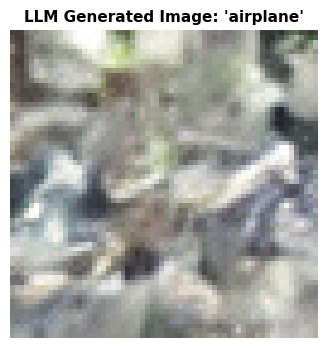

Successfully generated and untokenized 256 discrete tokens into pixels!
Generating image tokens conditioned on: 'A photo of a cat: <|start_img|>'...


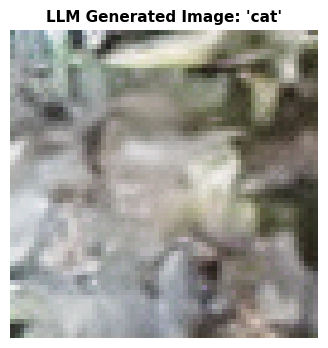

Successfully generated and untokenized 256 discrete tokens into pixels!


In [8]:
@torch.no_grad()
def generate_image_from_text(prompt_label="airplane", temperature=0.8):
    llm_model.eval()

    prompt = f"A photo of a {prompt_label}: <|start_img|>"
    input_ids = torch.tensor(llm_tokenizer.encode(prompt), dtype=torch.long, device=device).unsqueeze(0)

    print(f"Generating image tokens conditioned on: '{prompt}'...")
    generated = input_ids.clone()

    # Autoregressively sample the 256 visual tokens
    for step in range(NUM_VIS_TOKENS):
        outputs = llm_model(input_ids=generated)
        logits = outputs.logits[:, -1, :]

        # Restrict sampling strictly to the visual vocabulary range
        vis_logits = logits[:, TEXT_VOCAB_SIZE:UNIFIED_VOCAB_SIZE]
        probs = torch.softmax(vis_logits / temperature, dim=-1)
        next_vis_token = torch.multinomial(probs, num_samples=1)

        # Convert back to unified vocab ID
        next_token_id = next_vis_token + TEXT_VOCAB_SIZE
        generated = torch.cat([generated, next_token_id], dim=1)

    # Extract only the generated visual tokens
    gen_vis_ids = generated[0, input_ids.shape[1] : input_ids.shape[1] + NUM_VIS_TOKENS]
    # Unshift back to codebook IDs [0, 16383]
    codebook_ids = (gen_vis_ids - TEXT_VOCAB_SIZE).clamp(0, CODEBOOK_SIZE - 1)

    # De-tokenize integers back into RGB pixels using the VQ-GAN decoder
    reconstructed_pixels = untokenize(codebook_ids, H_lat, W_lat)

    # Display the result
    plt.figure(figsize=(4, 4))
    plt.imshow(reconstructed_pixels)
    plt.title(f"LLM Generated Image: '{prompt_label}'", fontsize=11, fontweight="bold")
    plt.axis("off")
    plt.show()

    print(f"Successfully generated and untokenized {len(codebook_ids)} discrete tokens into pixels!")

# Test generating an airplane and a cat
generate_image_from_text("airplane", temperature=0.7)
generate_image_from_text("cat", temperature=0.7)

## Now training longer!

Using `NUM_SAMPLES=1000`

In [ ]:
# ==============================================================================
# 6. Real Omni-Modal Training: Fine-Tuning an LLM on Discrete Image Tokens
# ==============================================================================

from torchvision.datasets import CIFAR10
from torchvision import transforms
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_ID = "distilgpt2"

print("Initializing tokenizer and expanding unified vocabulary...")
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_ID)
llm_model = AutoModelForCausalLM.from_pretrained(LLM_ID).to(device)

# Special multimodal delimiters
special_tokens = {"additional_special_tokens": ["<|start_img|>", "<|end_img|>"]}
llm_tokenizer.add_special_tokens(special_tokens)
llm_tokenizer.pad_token = llm_tokenizer.eos_token

START_IMG_ID = llm_tokenizer.convert_tokens_to_ids("<|start_img|>")
END_IMG_ID = llm_tokenizer.convert_tokens_to_ids("<|end_img|>")

# Unified vocabulary configuration
TEXT_VOCAB_SIZE = max(llm_tokenizer.vocab.values()) + 1
CODEBOOK_SIZE = vq_model.quantize.embedding.weight.shape[0]  # 16384
UNIFIED_VOCAB_SIZE = TEXT_VOCAB_SIZE + CODEBOOK_SIZE

llm_model.resize_token_embeddings(UNIFIED_VOCAB_SIZE)
print(f"Unified Vocab: {UNIFIED_VOCAB_SIZE} (Text: {TEXT_VOCAB_SIZE}, Visual: {CODEBOOK_SIZE})")

# Dedicated 64x64 preprocessor -> yields exactly 16x16 = 256 tokens from VQ-GAN
preprocess_64 = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# ------------------------------------------------------------------------------
# Collect Real CIFAR-10 Samples (Airplanes and Cats)
# ------------------------------------------------------------------------------
cifar_data = CIFAR10(root="./data", train=True, download=True)
selected_samples = []
target_classes = {0: "airplane", 3: "cat"}

NUM_SAMPLES = 1000

for img, label in cifar_data:
    if label in target_classes and len(selected_samples) < NUM_SAMPLES:
        selected_samples.append((img, target_classes[label]))
    if len(selected_samples) >= NUM_SAMPLES:
        break

print(f"Loaded {len(selected_samples)} real training images.")

# ------------------------------------------------------------------------------
# Pre-tokenize to Discrete Sequence
# ------------------------------------------------------------------------------
@torch.no_grad()
def encode_to_tokens_64(pil_image):
    tensor_img = preprocess_64(pil_image).unsqueeze(0).to(device)
    latents = vq_model.quant_conv(vq_model.encoder(tensor_img))
    B, C, H, W = latents.shape  # Expected: [1, 3, 16, 16]
    flat_latents = latents.permute(0, 2, 3, 1).reshape(-1, C)

    codebook = vq_model.quantize.embedding.weight
    dists = (
        torch.sum(flat_latents**2, dim=1, keepdim=True)
        + torch.sum(codebook**2, dim=1)
        - 2 * torch.matmul(flat_latents, codebook.t())
    )
    tokens = torch.argmin(dists, dim=1).clamp(0, CODEBOOK_SIZE - 1)
    return tokens, H, W

training_sequences = []
print("Tokenizing images with VQ-GAN...")

for img, label in selected_samples:
    vis_tokens, H_lat, W_lat = encode_to_tokens_64(img)
    shifted_vis_tokens = (vis_tokens + TEXT_VOCAB_SIZE).cpu().tolist()

    prompt = f"A photo of a {label}: <|start_img|>"
    prompt_ids = llm_tokenizer.encode(prompt)

    full_sequence = prompt_ids + shifted_vis_tokens + [END_IMG_ID]
    target_labels = ([-100] * len(prompt_ids)) + shifted_vis_tokens + [END_IMG_ID]

    seq_tensor = torch.tensor(full_sequence, dtype=torch.long)

    # Assert sequence length fits within GPT-2 context limit
    assert len(seq_tensor) <= 1024, f"Sequence length {len(seq_tensor)} exceeds GPT-2 limit (1024)"

    training_sequences.append({
        "input_ids": seq_tensor,
        "labels": torch.tensor(target_labels, dtype=torch.long)
    })

NUM_VIS_TOKENS = H_lat * W_lat
print(f"Latent grid: {H_lat}x{W_lat} -> {NUM_VIS_TOKENS} tokens per image.")
print(f"Total sequence length: {len(training_sequences[0]['input_ids'])} tokens (fits context budget).")

# ------------------------------------------------------------------------------
# Training Loop
# ------------------------------------------------------------------------------
optimizer = torch.optim.AdamW(llm_model.parameters(), lr=5e-4, weight_decay=1e-2)
EPOCHS = 12

print("\n=== Training LLM on Autoregressive Image Tokens ===")
llm_model.train()

for epoch in range(1, EPOCHS + 1):
    total_loss = 0.0
    # Inner progress bar tracking batches and instantaneous loss
    batch_bar = tqdm(
        training_sequences,
        desc=f"Epoch {epoch:02d}/{EPOCHS}",
        leave=False,
        unit="sample"
    )

    for step, seq in enumerate(batch_bar, start=1):
        input_ids = seq["input_ids"].unsqueeze(0).to(device)
        labels = seq["labels"].unsqueeze(0).to(device)

        optimizer.zero_grad()
        outputs = llm_model(input_ids=input_ids, labels=labels)
        loss = outputs.loss
        loss.backward()
        optimizer.step()

        cur_loss = loss.item()
        total_loss += cur_loss
        step_losses.append(cur_loss)

        # Real-time metrics in tqdm bar
        batch_bar.set_postfix({
            "step_loss": f"{cur_loss:.4f}",
            "running_avg": f"{(total_loss / step):.4f}"
        })

    avg_loss = total_loss / len(training_sequences)
    # if epoch % 3 == 0 or epoch == EPOCHS:
    print(f"Epoch {epoch:2d}/{EPOCHS} | Cross-Entropy Loss: {avg_loss:.4f}")

Generating image tokens conditioned on: 'A photo of a airplane: <|start_img|>'...


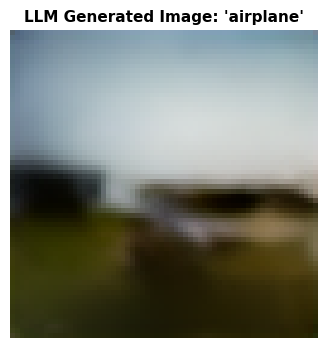

Successfully generated and untokenized 256 discrete tokens into pixels!
Generating image tokens conditioned on: 'A photo of a cat: <|start_img|>'...


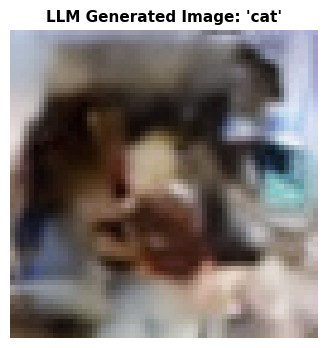

Successfully generated and untokenized 256 discrete tokens into pixels!


In [14]:
# Test generating an airplane and a cat
generate_image_from_text("airplane", temperature=0.7)
generate_image_from_text("cat", temperature=1.7)

Try using other models such as `LLM_ID = "HuggingFaceTB/SmolLM2-135M"`